# 📘 Módulo 27: El Algoritmo K-Means

Hola, deseamos darte la bienvenida al módulo **El Algoritmo K-Means** del curso Profesión Científico de Datos.

En este módulo exploraremos el algoritmo de agrupamiento K-Means, una técnica esencial de aprendizaje no supervisado para agrupar datos según la similitud de las observaciones. Se usa en análisis de mercado, física y muchas otras áreas para identificar nichos de oportunidad y diferencias entre grupos.

### 🎯 Objetivos de Aprendizaje

1. **Implementación del Algoritmo K-Means:** representar cada grupo por su **centroide** y asignar cada observación al centroide más cercano, repitiendo el proceso hasta que la agrupación se estabilice. Lo implementaremos **desde cero** y lo contrastaremos con Scikit-learn.
2. **Elegir el número de clústers (K):** usaremos el **Gráfico del Codo (Inercia)** y el **Índice de Silueta** como *guías* (no existe un "K óptimo" absoluto) y veremos qué ocurre cuando ambas señales no coinciden.
3. **Visualización, análisis y reducción de dimensionalidad:** con Pandas, Matplotlib, Seaborn y Scikit-learn, y **midiendo** (no suponiendo) el impacto de **estandarizar** y de aplicar **PCA** sobre la agrupación.

> **Cómo usar este cuaderno:** ejecuta las celdas en orden. Coloca `iris.csv` junto al cuaderno; si no está, se descargará de internet automáticamente. Las celdas de código con un `# 🔎` al inicio son las que conviene leer con calma.

## 📖 1. Teoría: Conociendo el Algoritmo K-Medias

El algoritmo K-Means busca particionar $n$ observaciones en $k$ clústers, donde cada observación pertenece al clúster cuyo valor medio (**centroide**) es el más cercano.

### ¿Cómo funciona internamente? (algoritmo de Lloyd)
1. **Inicialización:** se eligen $k$ centroides iniciales. La versión clásica los toma al azar; Scikit-learn usa por defecto **k-means++**, que los reparte de forma más separada para arrancar mejor.
2. **Asignación:** cada punto se asigna al centroide más cercano (distancia euclidiana).
3. **Actualización:** cada centroide se recalcula como el **promedio** de los puntos que tiene asignados.
4. **Iteración:** se repiten los pasos 2 y 3 hasta que las asignaciones dejan de cambiar (o se llega al máximo de iteraciones).

### 🎯 ¿Qué está optimizando?
K-Means minimiza la **inercia** (WCSS, *within-cluster sum of squares*): la suma de las distancias al cuadrado de cada punto a su centroide.

$$\text{Inercia} = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2$$

⚠️ **Cada iteración nunca empeora la inercia, pero el algoritmo solo garantiza un *óptimo local*:** según los centroides iniciales puede quedarse en una solución peor que la mejor posible. Por eso se ejecuta varias veces (`n_init`) y se conserva la mejor. Lo comprobaremos con datos.

### Evaluando el Modelo: ¿Cómo elegir K?
Como es aprendizaje no supervisado, no hay "Accuracy". Usamos dos guías:
* **Método del Codo (Inercia):** la inercia *siempre* baja al aumentar $k$ (con $k=n$ valdría 0). Buscamos el punto donde la mejora deja de ser drástica (el "codo"). Es una lectura **visual y a veces ambigua**.
* **Índice de Silueta:** para cada punto compara $a(i)$ (distancia media a su propio clúster) con $b(i)$ (distancia media al clúster vecino más cercano):

$$s(i) = \frac{b(i) - a(i)}{\max\big(a(i),\, b(i)\big)} \in [-1, 1]$$

  Cerca de 1 = bien agrupado; cerca de 0 = en la frontera; negativo = probablemente mal asignado. La silueta promedio favorece clústers **compactos y bien separados**.

### ⚖️ Supuestos y límites de K-Means
* Funciona mejor con clústers de forma **aproximadamente esférica** y tamaño parecido.
* Es **sensible a la escala** de las variables y a los valores atípicos.
* Hay que **fijar $k$ de antemano** y el resultado depende de la inicialización.

In [1]:
# 🛠️ Configuración inicial e importación de librerías
import warnings
from pathlib import Path
from typing import Any, Dict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 💻 2. Práctica: Agrupación K-Medias Dataset Iris

**El Reto:**
1. Obtener la base de datos "Iris.csv".
2. Agrupar las observaciones mediante K-Medias **sin transformar** los datos. Determinar el número de clústers (Codo y Silhouette).
3. Repetir el ejercicio tras reducir la dimensionalidad a 2 componentes mediante PCA (incluyendo la elección de $k$).
4. **Comparar resultados** de forma cuantitativa.

### 2.0 Datos: carga y auditoría
Leemos `iris.csv` localmente (y, si no existe, desde el repositorio de Seaborn). Las dos fuentes traen los **mismos datos con nombres de columna distintos** (`sepal.length`/`variety` vs `sepal_length`/`species`), así que los normalizamos. La especie real **no se usa para agrupar**: solo la guardaremos aparte para *evaluar* al final.

In [2]:
# 🔎 Carga robusta + auditoría básica
RUTA_LOCAL = Path("iris.csv")
URL_IRIS = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df_iris = pd.read_csv(RUTA_LOCAL if RUTA_LOCAL.exists() else URL_IRIS)
df_iris.columns = [c.replace(".", "_").lower() for c in df_iris.columns]
df_iris = df_iris.rename(columns={"variety": "species"})
df_iris["species"] = df_iris["species"].str.lower()

X_raw = df_iris.drop(columns="species")   # solo las 4 medidas (cm)
y_real = df_iris["species"]               # NO se usa para agrupar, solo para evaluar

print(f"Filas: {X_raw.shape[0]} | Variables: {X_raw.shape[1]} | Nulos: {int(X_raw.isna().sum().sum())} | Filas duplicadas: {int(df_iris.duplicated().sum())}")
print("Observaciones por especie:", y_real.value_counts().to_dict())
display(df_iris.head())
display(X_raw.describe().T[["min", "max", "mean", "std"]].round(2))

Filas: 150 | Variables: 4 | Nulos: 0 | Filas duplicadas: 1
Observaciones por especie: {'setosa': 50, 'versicolor': 50, 'virginica': 50}


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,min,max,mean,std
sepal_length,4.3,7.9,5.84,0.83
sepal_width,2.0,4.4,3.06,0.44
petal_length,1.0,6.9,3.76,1.77
petal_width,0.1,2.5,1.20,0.76


👆 **Lectura:** las 4 variables están **en centímetros** y en rangos comparables (aprox. 0.1 a 7.9 cm), aunque sus desviaciones difieren (los pétalos varían más que el ancho del sépalo). Hay 1 fila duplicada, algo normal en Iris y sin efecto relevante. Esto será importante cuando discutamos si **escalar** es imprescindible aquí.

### 2.1 Excursión: K-Means por dentro (desde cero)
El objetivo 1 del módulo es *implementar* el algoritmo. Este es el algoritmo de Lloyd en ~15 líneas de NumPy: asignar al centroide más cercano y promediar, hasta que los centroides no cambien. Lo ejecutamos con **inicialización aleatoria** y 10 semillas distintas para ver el riesgo del óptimo local.

In [3]:
def kmeans_desde_cero(X: np.ndarray, k: int, semilla: int, max_iter: int = 100):
    """K-Means (Lloyd) con inicialización aleatoria. Devuelve etiquetas, centroides, inercia e iteraciones."""
    rng = np.random.default_rng(semilla)
    centroides = X[rng.choice(len(X), size=k, replace=False)]          # 1. inicialización
    for it in range(1, max_iter + 1):
        dist = ((X[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2)
        etiquetas = dist.argmin(axis=1)                                 # 2. asignación
        nuevos = np.array([X[etiquetas == j].mean(axis=0) if (etiquetas == j).any() else centroides[j]
                           for j in range(k)])                          # 3. actualización
        if np.allclose(nuevos, centroides):                             # 4. convergencia
            break
        centroides = nuevos
    inercia = ((X - centroides[etiquetas]) ** 2).sum()
    return etiquetas, centroides, inercia, it

resultados = []
for semilla in range(10):
    _, _, inercia, iteraciones = kmeans_desde_cero(X_raw.values, k=3, semilla=semilla)
    resultados.append({"semilla": semilla, "iteraciones": iteraciones, "inercia": round(inercia, 2)})
df_semillas = pd.DataFrame(resultados).set_index("semilla")
display(df_semillas.T)

mejor_sklearn = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_raw).inertia_
print(f"Mejor inercia de nuestras 10 semillas: {df_semillas['inercia'].min():.2f} | Inercia de Scikit-learn (n_init=10): {mejor_sklearn:.2f}")

semilla,0,1,2,3,4,5,6,7,8,9
iteraciones,6.00,5.00,7.00,5.00,8.00,8.00,5.00,7.00,8.00,8.00
inercia,78.85,78.86,142.75,145.53,78.85,78.86,78.85,78.85,142.75,78.85


Mejor inercia de nuestras 10 semillas: 78.85 | Inercia de Scikit-learn (n_init=10): 78.85


👆 **Lectura:** varias semillas llegan a la misma inercia mínima (la de Scikit-learn), pero **otras se quedan en soluciones peores**: eso es un *óptimo local*. Con una sola ejecución podrías haber reportado una agrupación de peor calidad sin darte cuenta.

Comparemos ahora las dos estrategias de inicialización de Scikit-learn, **con una única ejecución (`n_init=1`) por semilla**, para ver cuánto ayuda *k-means++*:

In [4]:
filas = []
for init in ["random", "k-means++"]:
    inercias = [KMeans(n_clusters=3, init=init, n_init=1, random_state=s).fit(X_raw).inertia_ for s in range(30)]
    filas.append({"inicialización": init, "mejor inercia": round(min(inercias), 2), "peor inercia": round(max(inercias), 2),
                  "soluciones distintas": len(set(np.round(inercias, 1)))})
display(pd.DataFrame(filas).set_index("inicialización"))

,mejor inercia,peor inercia,soluciones distintas
inicialización,,,
random,78.85,145.45,3
k-means++,78.85,78.86,1


👆 **Lectura:** con inicialización aleatoria y una sola ejecución, las 30 semillas caen en **varias soluciones** (la peor con inercia casi el doble); con *k-means++* prácticamente todas alcanzan la mejor. Conclusión práctica: usa `k-means++` (por defecto) **y** `n_init` mayor que 1 (p. ej. 10) para que el resultado no dependa del azar.

### 2.2 Determinación del número de clústers (datos originales)
Evaluamos $k$ de 2 a 10 con inercia y silueta. Definimos funciones reutilizables porque repetiremos el análisis con PCA.

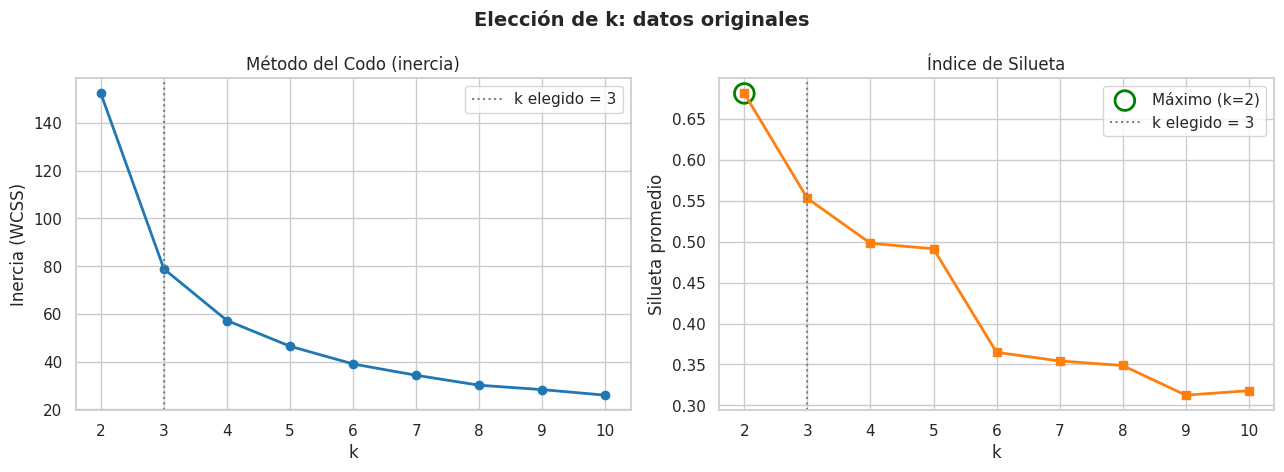

k,2,3,4,5,6,7,8,9,10
inercia,152.348,78.851,57.228,46.461,39.040,34.306,30.132,28.291,25.971
silueta,0.681,0.553,0.498,0.491,0.365,0.354,0.349,0.313,0.318


In [5]:
def evaluar_k(X, ks=range(2, 11), semilla=42) -> pd.DataFrame:
    """Inercia y silueta promedio para cada k."""
    filas = []
    for k in ks:
        modelo = KMeans(n_clusters=k, random_state=semilla, n_init=10).fit(X)
        filas.append({"k": k, "inercia": modelo.inertia_, "silueta": silhouette_score(X, modelo.labels_)})
    return pd.DataFrame(filas).set_index("k")


def graficar_k(res: pd.DataFrame, titulo: str, k_elegido: int = 3) -> None:
    """Codo (izquierda) y silueta (derecha) en paneles separados, con el k elegido marcado."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
    a1.plot(res.index, res["inercia"], marker="o", color="tab:blue", linewidth=2)
    a1.set_title("Método del Codo (inercia)"); a1.set_xlabel("k"); a1.set_ylabel("Inercia (WCSS)")
    a2.plot(res.index, res["silueta"], marker="s", color="tab:orange", linewidth=2)
    a2.set_title("Índice de Silueta"); a2.set_xlabel("k"); a2.set_ylabel("Silueta promedio")
    k_max = res["silueta"].idxmax()
    a2.scatter([k_max], [res.loc[k_max, "silueta"]], s=200, facecolors="none", edgecolors="green", linewidths=2, label=f"Máximo (k={k_max})")
    for ax in (a1, a2):
        ax.axvline(k_elegido, color="gray", linestyle=":", label=f"k elegido = {k_elegido}")
        ax.legend()
    fig.suptitle(titulo, fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()


res_raw = evaluar_k(X_raw)
graficar_k(res_raw, "Elección de k: datos originales")
display(res_raw.round(3).T)

### 🧠 Interpretación honesta: las dos señales no coinciden del todo
* **Codo:** la inercia cae con fuerza al pasar de $k=2$ a $k=3$ y luego la mejora se modera: hay una inflexión razonable en $k=3$, pero el codo es una lectura visual y no es nítida.
* **Silueta:** el máximo está en **$k=2$** (≈ 0.68) y en $k=3$ baja (≈ 0.55).

¿Por qué la silueta prefiere $k=2$? Veámoslo: con $k=2$ K-Means separa **Setosa** del resto, porque *Versicolor* y *Virginica* se traslapan en el espacio de medidas.

In [6]:
etiquetas_k2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X_raw)
display(pd.crosstab(y_real, etiquetas_k2, rownames=["especie real"], colnames=["clúster (k=2)"]))

clúster (k=2),0,1
especie real,,
setosa,0,50
versicolor,47,3
virginica,50,0


👆 Con $k=2$ hay un grupo casi puro de Setosa y otro que mezcla Versicolor y Virginica. **Las métricas no "saben" que existen 3 especies**: midieron que hay dos bloques bien separados.

**¿Entonces por qué usamos $k=3$?** Es una **decisión que combina evidencia y contexto**, y conviene decirlo así: (a) el codo muestra una inflexión en 3, (b) la silueta en $k=3$ sigue siendo aceptable (> 0.5) y (c) **por conocimiento del dominio** sabemos que hay 3 especies. No es "el óptimo matemático", ni una decisión tomada solo con las métricas.

### 2.3 K-Means definitivo (datos originales) y validación externa
Entrenamos con $k=3$ y, como en Iris **sí conocemos** la especie, la usamos **solo para evaluar** (validación externa) con una tabla cruzada y el *Adjusted Rand Index* (ARI: 1 = coincide perfectamente, ≈ 0 = como el azar).

In [7]:
kmeans_raw = KMeans(n_clusters=3, random_state=42, n_init=10)
etq_raw = kmeans_raw.fit_predict(X_raw)
df_iris["cluster_raw"] = etq_raw

print("Centros de los clústers (datos originales, en cm):")
display(pd.DataFrame(kmeans_raw.cluster_centers_, columns=X_raw.columns).round(2))

print("Especie real vs. clúster asignado:")
display(pd.crosstab(y_real, etq_raw, rownames=["especie real"], colnames=["clúster"]))
print(f"ARI vs. especie real: {adjusted_rand_score(y_real, etq_raw):.3f}")
print(f"Silueta de esta agrupación: {silhouette_score(X_raw, etq_raw):.3f}  |  Silueta si usáramos las especies reales como grupos: {silhouette_score(X_raw, y_real):.3f}")

Centros de los clústers (datos originales, en cm):


,sepal_length,sepal_width,petal_length,petal_width
0,5.90,2.75,4.39,1.43
1,5.01,3.43,1.46,0.25
2,6.85,3.07,5.74,2.07


Especie real vs. clúster asignado:


clúster,0,1,2
especie real,,,
setosa,0,50,0
versicolor,48,0,2
virginica,14,0,36


ARI vs. especie real: 0.730
Silueta de esta agrupación: 0.553  |  Silueta si usáramos las especies reales como grupos: 0.503


👆 **Lectura:**
* Setosa queda en un clúster propio y puro. El error está en la frontera **Versicolor ↔ Virginica** (unos 16 puntos quedan fuera de la especie dominante de su clúster).
* **Los números de clúster (0, 1, 2) son arbitrarios**: lo que importa es qué puntos agrupan, no su etiqueta.
* Un dato curioso: la silueta de K-Means (≈ 0.55) es *mayor* que la de las especies reales (≈ 0.50). Es decir, **una silueta alta no significa "coincidir con las clases reales"**: mide compacidad y separación geométrica, no significado.

### 2.4 Estandarización y PCA (por pasos)
Hasta ahora usamos los datos tal cual. Ahora introducimos **dos transformaciones distintas** que conviene no confundir:
1. **Estandarizar** (media 0 y desviación 1): cambia *cuánto pesa cada variable* en la distancia.
2. **PCA** a 2 componentes: *rota* los ejes y descarta la información de los componentes menos importantes.

En la versión original del ejercicio ambas se aplican juntas, así que no se puede saber a cuál se debe un cambio. Aquí las **separamos** para poder medirlas.

In [8]:
# 1. Estandarización
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 2. PCA sobre los datos estandarizados
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Varianza explicada por PC1 y PC2: {pca.explained_variance_ratio_[0]*100:.1f}% + {pca.explained_variance_ratio_[1]*100:.1f}% = {pca.explained_variance_ratio_.sum()*100:.2f}%")
print("\nCargas (qué variables forman cada componente):")
display(pd.DataFrame(pca.components_.T, index=X_raw.columns, columns=["PC1", "PC2"]).round(2))

Varianza explicada por PC1 y PC2: 73.0% + 22.9% = 95.81%

Cargas (qué variables forman cada componente):


,PC1,PC2
sepal_length,0.52,0.38
sepal_width,-0.27,0.92
petal_length,0.58,0.02
petal_width,0.56,0.07


👆 **Lectura:** PC1 y PC2 conservan ≈ 95.8 % de la varianza, así que en Iris **el gráfico 2D es una representación fiel** (a diferencia de datasets donde 2 componentes explican poco). PC1 mezcla sobre todo las medidas de **largo del sépalo y de los pétalos** (tamaño general de la flor); PC2 está dominado por el **ancho del sépalo**. El signo de los componentes es arbitrario.

### 2.5 Elegir $k$ y agrupar sobre los componentes PCA
El reto pide *repetir el ejercicio*, lo que incluye volver a elegir $k$ (en la versión original se fijó $k=3$ directamente).

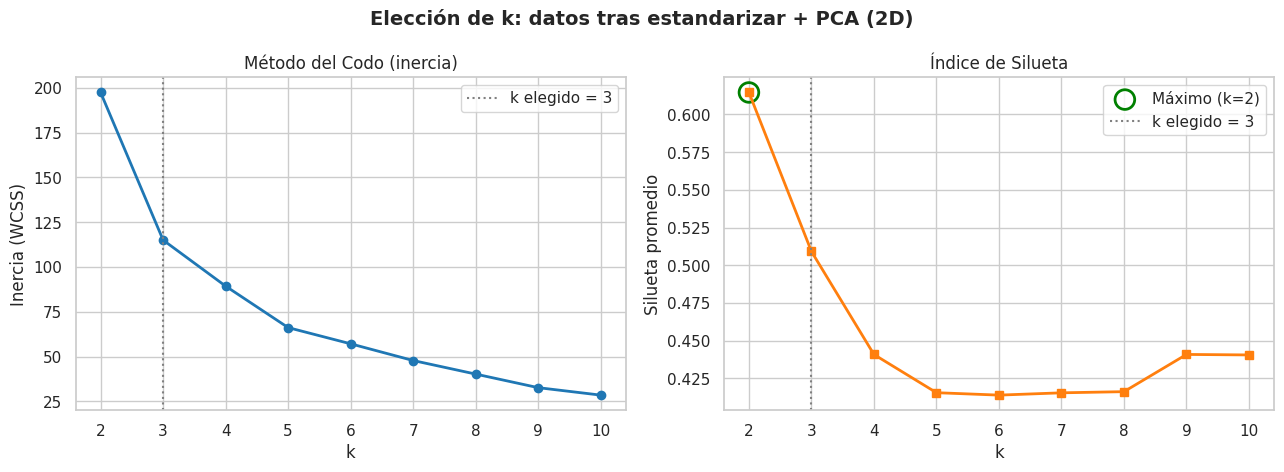

k,2,3,4,5,6,7,8,9,10
inercia,197.404,115.021,89.341,66.199,57.159,47.830,40.266,32.692,28.529
silueta,0.615,0.509,0.441,0.416,0.414,0.415,0.416,0.441,0.441


In [9]:
res_pca = evaluar_k(X_pca)
graficar_k(res_pca, "Elección de k: datos tras estandarizar + PCA (2D)")
display(res_pca.round(3).T)

👆 **Lectura:** el patrón es el mismo que con los datos originales: la silueta máxima sigue en $k=2$ (≈ 0.62) y $k=3$ queda en ≈ 0.51. Mantenemos $k=3$ por las mismas razones (inflexión del codo + contexto de 3 especies). Ahora agrupamos y graficamos: a la izquierda los clústers de K-Means, a la derecha las **especies reales** sobre los mismos ejes, para comparar visualmente.

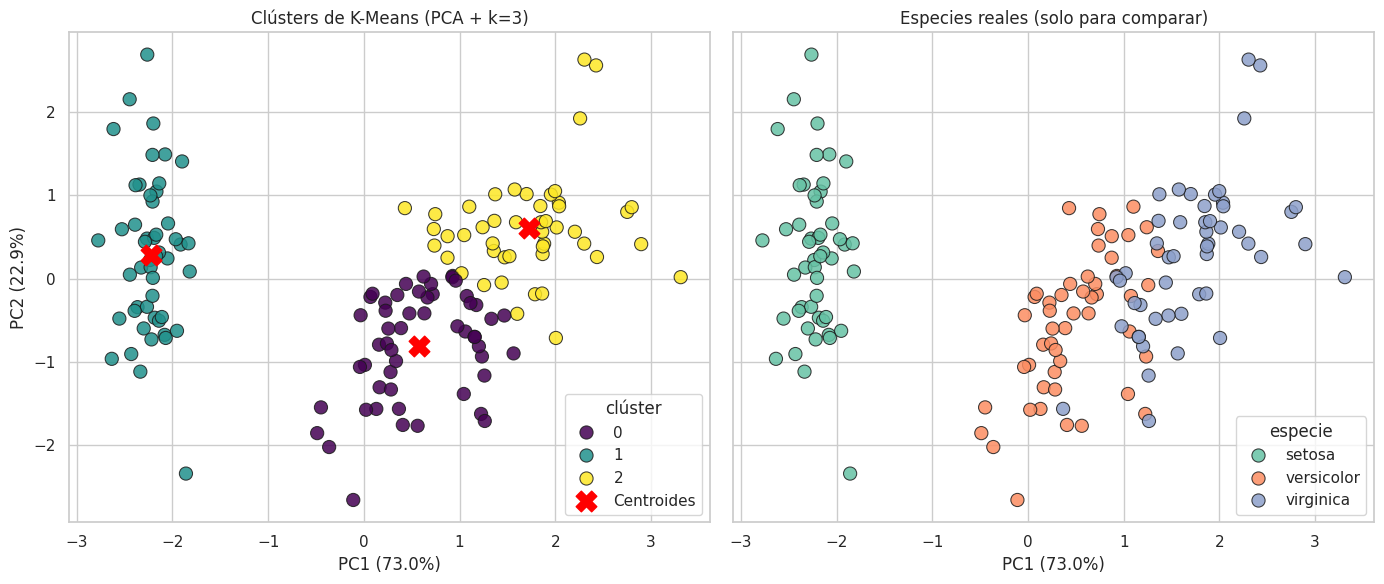

In [10]:
kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init=10)
etq_pca = kmeans_pca.fit_predict(X_pca)
df_iris["cluster_pca"] = etq_pca

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=etq_pca, palette="viridis", s=90, alpha=0.85, edgecolor="k", ax=ax1)
ax1.scatter(*kmeans_pca.cluster_centers_.T, c="red", s=220, marker="X", label="Centroides")
ax1.set_title("Clústers de K-Means (PCA + k=3)"); ax1.legend(title="clúster")
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_real, palette="Set2", s=90, alpha=0.85, edgecolor="k", ax=ax2)
ax2.set_title("Especies reales (solo para comparar)"); ax2.legend(title="especie")
for ax in (ax1, ax2):
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.tight_layout(); plt.show()

### 2.6 Comparación cuantitativa de resultados (Inciso 2 vs Inciso 3)
El cuaderno original afirmaba que los resultados eran "altamente consistentes" y que el PCA "limpia las fronteras", pero **nunca lo medía**. Comparamos tres variantes con $k=3$:
* **Originales (4D)**, **Estandarizados (4D)** (aísla el efecto de escalar) y **PCA (2D)**.

Medimos: ARI contra la especie real, ARI contra la agrupación original, y cuántos puntos quedan fuera de la especie dominante de su clúster.

In [11]:
etq_esc = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled)   # estandarizado, SIN PCA

def puntos_fuera(etiquetas) -> int:
    """Puntos que no pertenecen a la especie dominante de su clúster."""
    tabla = pd.crosstab(y_real, etiquetas)
    return int(len(y_real) - tabla.max(axis=0).sum())

variantes = {"Originales (4D)": etq_raw, "Estandarizados (4D)": etq_esc, "PCA (2D)": etq_pca}
comparacion = pd.DataFrame({
    nombre: {
        "ARI vs especie real": round(adjusted_rand_score(y_real, etq), 3),
        "ARI vs originales": round(adjusted_rand_score(etq_raw, etq), 3),
        "Puntos fuera de su especie dominante": puntos_fuera(etq),
    } for nombre, etq in variantes.items()
}).T
comparacion["Puntos fuera de su especie dominante"] = comparacion["Puntos fuera de su especie dominante"].astype(int)
display(comparacion)

print(f"ARI entre 'Estandarizados (4D)' y 'PCA (2D)': {adjusted_rand_score(etq_esc, etq_pca):.3f}")

,ARI vs especie real,ARI vs originales,Puntos fuera de su especie dominante
Originales (4D),0.73,1.000,16
Estandarizados (4D),0.62,0.804,25
PCA (2D),0.62,0.804,25


ARI entre 'Estandarizados (4D)' y 'PCA (2D)': 1.000


### 🧠 Qué nos dicen los datos (y qué no)
1. **Los resultados no son idénticos:** estandarizar cambia la agrupación (ARI ≈ 0.80 contra la original): unos 9 puntos más quedan fuera de su especie dominante (25 frente a 16).
2. **El PCA de 2 componentes no cambió nada respecto a solo estandarizar:** el ARI entre "Estandarizados (4D)" y "PCA (2D)" es **1.0** (mismas asignaciones). Es decir, **la diferencia viene de la estandarización, no del PCA**. Con Iris, que tiene 95.8 % de varianza en 2 componentes, descartar los otros dos no altera los grupos.
3. **La afirmación "el PCA limpia el ruido y mejora las fronteras" no se sostiene en este caso:** la agrupación sobre PCA coincide *menos* con las especies reales (ARI ≈ 0.62) que la de los datos originales (≈ 0.73). Una posible explicación: al estandarizar, el ancho del sépalo (poco discriminante entre especies) pasa a pesar igual que las medidas de los pétalos (muy discriminantes). *Mejor coincidencia con las especies no es el objetivo de un método no supervisado, pero aquí sirve como chequeo porque conocemos las clases.*
4. **Escalar no es "innegociable" en todos los casos:** cuando las variables ya están en la **misma unidad** (aquí, cm) es una *decisión* que conviene evaluar; cuando las unidades o rangos son muy distintos (p. ej. edad y salario) sí es indispensable.

### ✅ Ventajas reales del PCA antes de K-Means
* **Visualización:** permite graficar en 2D; en Iris sin casi pérdida de información (95.8 %). *Esta es su ventaja demostrada aquí.*
* **Dimensionalidad alta:** en espacios de decenas o cientos de variables, la distancia euclidiana pierde capacidad de discriminar y PCA puede ayudar. **Con 4 variables este problema no existe**, así que no es una ventaja observable en Iris.
* **Rendimiento:** reducir columnas acelera el cómputo en datasets masivos; con 150 filas es irrelevante.
* **Cuidado:** PCA no "mejora matemáticamente" las distancias: las **conserva de forma aproximada** y descarta información.

## 🚀 3. Versión Pro: Llevando K-Means a Producción

En producción no ejecutamos scripts sueltos: usamos **Pipelines** (la misma secuencia de transformaciones para datos de entrenamiento y datos nuevos), **POO** y validaciones. La clase original tenía tres problemas que corregimos:

1. **`n_init="auto"` no equivale a `n_init=10`:** con k-means++ ejecuta *una sola* inicialización, por lo que podía caer en un óptimo local peor que el de la sección 2.4 (lo mostramos justo después de la clase).
2. **No tenía `predict`:** la conclusión decía que "los nuevos usuarios siguen los mismos pasos", pero la clase solo sabía entrenar. Sin `predict` no se puede asignar un dato nuevo.
3. **Detalles:** las métricas salían como `np.float64(...)`, había imports sin usar y un bloque `if __name__ == "__main__"` que no tiene sentido en un cuaderno.

In [12]:
import logging

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s", force=True)


class KMeansRecommenderPro:
    """Pipeline de producción: estandarización -> PCA (opcional) -> K-Means, con fit/predict/métricas."""

    def __init__(self, n_clusters: int, use_pca: bool = True, n_components: int = 2,
                 n_init: int = 10, random_state: int = 42):
        self.n_clusters = n_clusters
        self.use_pca = use_pca
        self.n_components = n_components
        self.n_init = n_init
        self.random_state = random_state
        self.pipeline = self._build_pipeline()

    def _build_pipeline(self) -> Pipeline:
        steps = [("scaler", StandardScaler())]
        if self.use_pca:
            steps.append(("pca", PCA(n_components=self.n_components)))
        steps.append(("kmeans", KMeans(n_clusters=self.n_clusters, n_init=self.n_init, random_state=self.random_state)))
        return Pipeline(steps)

    @staticmethod
    def _validar(X: pd.DataFrame) -> None:
        if X.isna().any().any():
            raise ValueError("X contiene valores nulos; imputa o elimina antes de entrenar.")

    def fit(self, X: pd.DataFrame) -> "KMeansRecommenderPro":
        self._validar(X)
        logging.info(f"Entrenando con {X.shape[0]} filas y {X.shape[1]} variables.")
        self.pipeline.fit(X)
        self.columns_ = list(X.columns)
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        """Asigna clúster a datos NUEVOS usando el scaler/PCA/centroides ya ajustados."""
        self._validar(X)
        return self.pipeline.predict(X[self.columns_])

    def fit_predict(self, X: pd.DataFrame) -> np.ndarray:
        return self.fit(X).predict(X)

    def get_metrics(self, X: pd.DataFrame) -> Dict[str, Any]:
        """Silueta e inercia, medidas en el espacio donde realmente se agrupó (no son comparables entre espacios distintos)."""
        espacio = self.pipeline[:-1].transform(X[self.columns_])
        etiquetas = self.pipeline.predict(X[self.columns_])
        metricas = {
            "silueta": round(float(silhouette_score(espacio, etiquetas)), 4),
            "inercia": round(float(self.pipeline.named_steps["kmeans"].inertia_), 2),
        }
        if self.use_pca:
            metricas["varianza_explicada"] = round(float(self.pipeline.named_steps["pca"].explained_variance_ratio_.sum()), 4)
        return metricas


# --- Uso ---
modelo_prod = KMeansRecommenderPro(n_clusters=3, use_pca=True).fit(X_raw)
etq_prod = modelo_prod.predict(X_raw)
print("\nMétricas:", modelo_prod.get_metrics(X_raw))
print(f"ARI contra la agrupación manual de la sección 2.5: {adjusted_rand_score(etq_pca, etq_prod):.3f}  (1.0 = el pipeline reproduce exactamente el análisis)")

# Dato nuevo: una flor con medidas típicas de Setosa
flor_nueva = pd.DataFrame([[5.0, 3.4, 1.5, 0.2]], columns=X_raw.columns)
cluster_nuevo = int(modelo_prod.predict(flor_nueva)[0])
especie_dominante = y_real[etq_prod == cluster_nuevo].mode()[0]
print(f"Flor nueva -> clúster {cluster_nuevo} (especie dominante en ese clúster: {especie_dominante})")

2026-09-30 20:05:07,404 - INFO - Entrenando con 150 filas y 4 variables.



Métricas: {'silueta': 0.5092, 'inercia': 115.02, 'varianza_explicada': 0.9581}
ARI contra la agrupación manual de la sección 2.5: 1.000  (1.0 = el pipeline reproduce exactamente el análisis)
Flor nueva -> clúster 1 (especie dominante en ese clúster: setosa)


#### ⚠️ La trampa de `n_init="auto"`
Repetimos el mismo pipeline **solo cambiando `n_init`** de 10 a `"auto"` (que con k-means++ equivale a una única ejecución):

In [13]:
def pipeline_con_n_init(n_init):
    return Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=2)),
                     ("kmeans", KMeans(n_clusters=3, n_init=n_init, random_state=42))])

filas = []
for n_init in [10, "auto"]:
    p = pipeline_con_n_init(n_init)
    etq = p.fit_predict(X_raw)
    filas.append({"n_init": str(n_init), "inercia": round(p.named_steps["kmeans"].inertia_, 2),
                  "silueta": round(silhouette_score(p[:-1].transform(X_raw), etq), 4),
                  "ARI vs análisis manual (2.5)": round(adjusted_rand_score(etq_pca, etq), 3)})
display(pd.DataFrame(filas).set_index("n_init"))

,inercia,silueta,ARI vs análisis manual (2.5)
n_init,,,
10,115.02,0.5092,1.00
auto,166.04,0.5228,0.43


👆 **Lectura:** con `n_init="auto"` la inercia es **bastante mayor** (peor solución para el objetivo de K-Means) y las asignaciones **ya no coinciden** con el análisis manual. Curiosamente su silueta es un poco *más alta*: otra muestra de que **inercia y silueta miden cosas distintas** y de que conviene revisar ambas. Regla práctica: si necesitas reproducir un análisis, fija `n_init` explícitamente.

## ⚖️ 4. Limitaciones y buenas prácticas
1. **El resultado depende de la inicialización:** usa k-means++ y `n_init` ≥ 10; fija `random_state` para reproducir.
2. **No existe un $k$ correcto único:** combina codo, silueta y criterio de dominio, y **explica** la decisión (como hicimos en Iris).
3. **Silueta ≠ verdad:** favorece grupos compactos y separados; puede preferir $k=2$ aunque haya 3 clases (Iris) y no mide si los grupos "tienen sentido".
4. **Supone clústers esféricos y de tamaño parecido:** con formas alargadas o densidades distintas, otros algoritmos (DBSCAN, jerárquico, mezclas gaussianas) pueden funcionar mejor.
5. **Sensible a escala y a atípicos:** evalúa si estandarizar (obligatorio con unidades distintas; una decisión con unidades iguales) y revisa los valores extremos.
6. **Preprocesar no siempre mejora:** mide el efecto de cada transformación por separado, como en la sección 2.6.
7. **Las etiquetas de clúster son arbitrarias:** interpreta los **centroides/perfiles**, no el número.

## 🧪 5. Ejercicios propuestos
1. Repite la sección 2.3 con $k=2$ y $k=4$. ¿Qué ocurre con las tres especies? ¿Qué clúster se divide?
2. Ejecuta `kmeans_desde_cero` con `k=3` y 100 semillas: ¿qué porcentaje alcanza la mejor inercia? Luego implementa la inicialización k-means++.
3. Agrupa con **solo las dos medidas de los pétalos** (`petal_length`, `petal_width`) sin PCA. ¿Mejora el ARI contra las especies? ¿Por qué?
4. Calcula cuántos componentes necesitas para explicar el 99 % de la varianza y repite la comparación de la sección 2.6.
5. Usa `modelo_prod.predict` con una flor de medidas típicas de Virginica (p. ej. 6.8, 3.0, 5.6, 2.1). ¿En qué clúster cae?

## 📚 6. Glosario (Módulo 27)

* **Centroide:** punto que representa el centro de un clúster; se calcula como el promedio de las observaciones asignadas a él.
* **Clúster:** grupo de observaciones similares entre sí formado durante el agrupamiento.
* **Inercia (WCSS):** suma de las distancias al cuadrado de cada punto a su centroide. Es lo que K-Means minimiza; siempre baja al aumentar $k$.
* **Gráfico del codo (Elbow Method):** gráfico de la inercia frente a $k$; se busca el punto donde la mejora deja de ser drástica. Su lectura es visual y a veces ambigua.
* **Índice de silueta:** métrica de −1 a 1 que compara la cohesión de un punto con su clúster frente a la separación del clúster vecino. Favorece grupos compactos y separados.
* **K-Means:** algoritmo de agrupamiento que reparte las observaciones en $k$ grupos alternando asignación al centroide más cercano y actualización de centroides.
* **k-means++:** estrategia de inicialización que reparte los centroides iniciales de forma separada; es el valor por defecto en Scikit-learn.
* **n_init:** número de veces que se ejecuta K-Means con distintos centroides iniciales; se conserva la solución con menor inercia.
* **Óptimo local:** solución que no puede mejorarse con pequeños cambios pero no es necesariamente la mejor posible; K-Means solo garantiza esto.
* **Optimización:** en K-Means, el proceso iterativo de minimizar la inercia (no el "ajuste de parámetros").
* **Estandarización:** transformar cada variable a media 0 y desviación estándar 1 para que pesen de forma comparable en la distancia.
* **PCA (Análisis de Componentes Principales):** método que rota los ejes para obtener componentes no correlacionados, ordenados por la varianza que explican, y permite reducir dimensiones.
* **Varianza explicada:** porcentaje de la variabilidad total que conserva cada componente.
* **ARI (Adjusted Rand Index):** mide la coincidencia entre dos agrupaciones: 1 = idénticas; ≈ 0 = como el azar.
* **Pipeline:** secuencia de transformaciones y modelo que se ajusta y aplica de forma idéntica a datos de entrenamiento y nuevos.
* **Scikit-learn:** biblioteca de Python con K-Means, PCA, métricas y pipelines.

## 🎯 7. Conclusiones

1. **K-Means convierte "agrupar" en minimizar distancias:** alterna asignar al centroide más cercano y promediar. Lo implementamos en pocas líneas, pero solo garantiza un **óptimo local**, por eso se usan k-means++ y varias inicializaciones (`n_init`).
2. **Elegir $k$ es una decisión, no un cálculo:** en Iris el codo sugiere 3 y la silueta prefiere 2 (porque Versicolor y Virginica se traslapan). Elegimos $k=3$ combinando ambas señales **con el conocimiento del dominio**, y lo dijimos explícitamente.
3. **Preprocesar hay que medirlo, no suponerlo:** estandarizar cambió la agrupación (ARI ≈ 0.80 frente a la original) y el PCA de 2 componentes no añadió ningún cambio sobre eso (ARI = 1.0). Su ventaja demostrada en Iris es la **visualización** con ≈ 96 % de la varianza; las demás (alta dimensionalidad, rendimiento) no aplican con 4 variables y 150 filas.
4. **Las métricas miden cosas distintas:** la silueta no equivale a "coincidir con las clases reales", y silueta e inercia pueden contradecirse.
5. **Del notebook a producción:** un Pipeline con `fit`, `predict` y `n_init` explícito garantiza que datos nuevos reciban exactamente las mismas transformaciones y que el análisis sea **reproducible**; un detalle como `n_init="auto"` puede cambiar el resultado sin avisar.